In [1]:
using CSV, DataFrames, Statistics, CategoricalArrays, Plots
isdefined(Main, :IAI) || error("IAI is not loaded: switch to the Julia kernel that uses the IAI system image")

const SEED = 15095
df = CSV.read("subscribers.csv", DataFrame; types = Dict(:snapshot_month => String))
println(size(df))

(54331

, 15)


## Part (a)

### Training months

monthly-billing churn rate: Jan–Aug 2025 = 0.11, Sep 2025–Apr 2026 = 0.32
max active_days_30d: Jan–Aug 2025 = 30, Sep 2025–Apr 2026 = 15


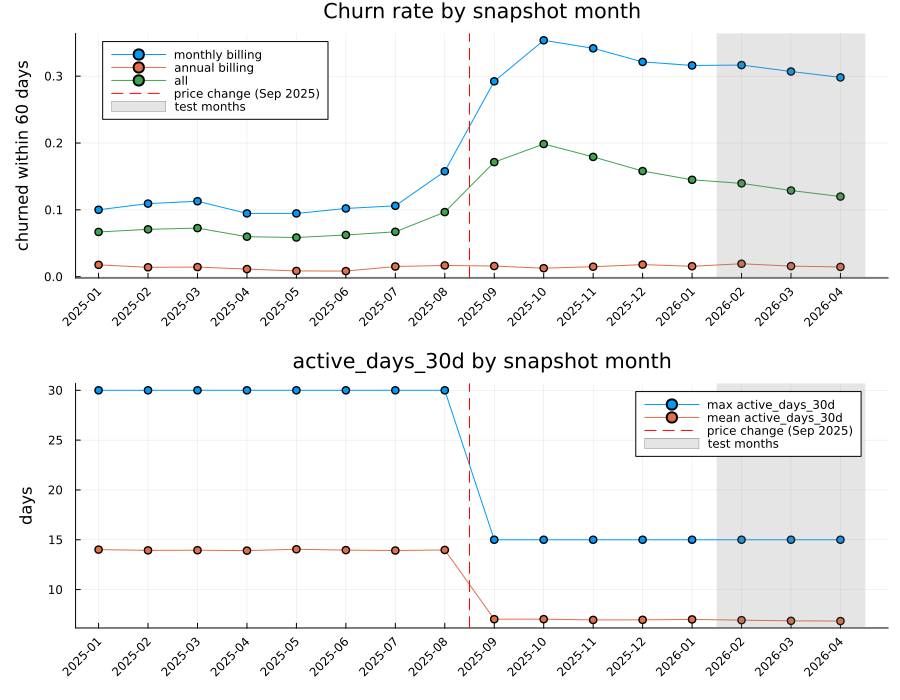

In [2]:
by_month = sort(combine(groupby(df, :snapshot_month),
    :churned_60d     => mean    => :churn_rate,
    :active_days_30d => mean    => :mean_active_days,
    :active_days_30d => maximum => :max_active_days), :snapshot_month)
churn_billing = sort(unstack(
    combine(groupby(df, [:snapshot_month, :billing]), :churned_60d => mean => :churn_rate),
    :snapshot_month, :billing, :churn_rate), :snapshot_month)

months = by_month.snapshot_month
xs = 1:length(months)
i_sep = findfirst(==("2025-09"), months)   # first post-price-change snapshot
i_feb = findfirst(==("2026-02"), months)   # first test month

p1 = plot(xs, [churn_billing.monthly churn_billing.annual by_month.churn_rate],
          label = ["monthly billing" "annual billing" "all"], marker = :circle,
          ylabel = "churned within 60 days", title = "Churn rate by snapshot month")
p2 = plot(xs, [by_month.max_active_days by_month.mean_active_days],
          label = ["max active_days_30d" "mean active_days_30d"], marker = :circle,
          ylabel = "days", title = "active_days_30d by snapshot month")
for p in (p1, p2)
    vline!(p, [i_sep - 0.5], color = :red, linestyle = :dash, label = "price change (Sep 2025)")
    vspan!(p, [i_feb - 0.5, length(months) + 0.5], color = :gray, alpha = 0.2, label = "test months")
    plot!(p, xticks = (xs, months), xrotation = 45)
end
fig_months = plot(p1, p2, layout = (2, 1), size = (900, 700), left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
savefig(fig_months, "churn_by_month.png")

before, after = df.snapshot_month .<= "2025-08", df.snapshot_month .>= "2025-09"
monthly = df.billing .== "monthly"
println("monthly-billing churn rate: Jan–Aug 2025 = ", round(mean(df.churned_60d[before .& monthly]), digits = 3),
        ", Sep 2025–Apr 2026 = ", round(mean(df.churned_60d[after .& monthly]), digits = 3))
println("max active_days_30d: Jan–Aug 2025 = ", maximum(df.active_days_30d[before]),
        ", Sep 2025–Apr 2026 = ", maximum(df.active_days_30d[after]))
display("image/png", fig_months)

**Training months.** I use September 2025 through January 2026 for training. September marks a clear regime change: monthly-billing churn increases from 11% in January–August 2025 to 32% afterward, while the maximum active_days_30d falls from 30 to 15. I therefore use the post-change months for training and reserve February–April 2026 as the test set.f

### Keep/drop evidence

In [3]:
r3(x) = round(x, digits = 3)
pct(x) = string(round(100x, digits = 1), "%")
churn_by(col) = combine(groupby(df, col), :churned_60d => mean => :rate)
rng(col) = (t = churn_by(col); "$(pct(minimum(t.rate)))–$(pct(maximum(t.rate)))")

# last_invoice_usd: same value in every row of a subscriber -> read at extraction (30 Jun 2026), not at the snapshot
subs = combine(groupby(df, :subscriber_id),
    :last_invoice_usd => (x -> length(unique(x)) == 1) => :constant,
    :last_invoice_usd => first                         => :inv,
    :churned_60d      => maximum                       => :ever_churned)
list_price = in.(subs.inv, Ref(Set([20.0, 25.0, 240.0, 300.0])))
ever_zero, ever_other = mean(subs.ever_churned[subs.inv .== 0]), mean(subs.ever_churned[.!list_price .& (subs.inv .!= 0)])

# signup_channel: age mix of student_promo
promo_young = mean(df.age_band[df.signup_channel .== "student_promo"] .== "18-24")

tenure_rate(m) = mean(df.churned_60d[m])
fp = df.failed_payment_30d .== 1

keep_drop = DataFrame(
    column = ["subscriber_id", "snapshot_month", "age_band", "signup_channel", "last_invoice_usd",
              "billing", "tenure_months", "region",
              "active_days_30d, usage_trend, features_used, days_since_last_login",
              "support_tickets_90d, failed_payment_30d", "churned_60d"],
    decision = ["drop", "drop", "drop", "drop", "drop",
                "keep", "keep", "keep", "keep", "keep", "label"],
    evidence = [
        "corr with tenure_months = $(r3(cor(df.subscriber_id, df.tenure_months)))",
        "time index; monthly-billing churn jumps at Sep 2025 (plot above)",
        "company policy; churn by band $(rng(:age_band))",
        "student_promo is $(pct(promo_young)) age 18–24",
        "constant across all rows for $(pct(mean(subs.constant))) of subscribers; ever churned: $(sum(subs.ever_churned[list_price])) of $(sum(list_price)) at list price vs $(pct(ever_zero)) at \$0 and $(pct(ever_other)) other",
        "churn: annual $(pct(mean(df.churned_60d[.!monthly]))) vs monthly $(pct(mean(df.churned_60d[monthly])))",
        "churn: tenure ≤ 3 months $(pct(tenure_rate(df.tenure_months .<= 3))) vs > 24 months $(pct(tenure_rate(df.tenure_months .> 24)))",
        "churn by region $(rng(:region))",
        "usage measured in the 30 days before the snapshot",
        "churn: failed payment $(pct(mean(df.churned_60d[fp]))) vs none $(pct(mean(df.churned_60d[.!fp])))",
        "target"])

Row,column,decision,evidence
,String,String,String
1,subscriber_id,drop,corr with tenure_months = -0.951
2,snapshot_month,drop,time index; monthly-billing churn jumps at Sep 2025 (plot above)
3,age_band,drop,company policy; churn by band 10.7%–12.0%
4,signup_channel,drop,student_promo is 94.2% age 18–24
5,last_invoice_usd,drop,constant across all rows for 100.0% of subscribers; ever churned: 1 of 2291 at list price vs 95.2% at $0 and 91.6% other
6,billing,keep,churn: annual 1.5% vs monthly 19.7%
7,tenure_months,keep,churn: tenure ≤ 3 months 23.0% vs > 24 months 7.0%
8,region,keep,churn by region 10.8%–11.2%
9,"active_days_30d, usage_trend, features_used, days_since_last_login",keep,usage measured in the 30 days before the snapshot


We drop `subscriber_id` because it is an account identifier rather than a meaningful predictive feature; its strong correlation with tenure ($r=-0.951$) also suggests that it encodes information about when a subscriber joined. We drop `snapshot_month` because it is a time index that directly captures the pre- versus post-policy regime rather than subscriber behavior. We exclude `age_band` because company policy prohibits targeting based on age, and we also exclude `signup_channel` because it can act as a strong proxy for age: 94.2% of subscribers from `student_promo` are ages 18--24. Finally, we drop `last_invoice_usd` because it is constant across all monthly snapshots for each subscriber, suggesting that it was measured at extraction rather than at the historical snapshot and could therefore introduce leakage.

### Features and splits

We construct the full and kept-feature datasets and reserve February–April 2026 as the test set. The two OCTs below use all observations through January 2026 as required.

In [4]:
const CAT_COLS = ["billing", "region", "age_band", "signup_channel"]

all_cols  = setdiff(names(df), ["snapshot_month", "churned_60d"])   # model (1)
kept_cols = ["billing", "tenure_months", "region",
             "active_days_30d", "usage_trend", "features_used",
             "support_tickets_90d", "failed_payment_30d", "days_since_last_login"]

# Build feature tables once on the full data so categorical levels are shared across splits
function make_X(d, cols)
    X = select(d, cols)
    for c in intersect(cols, CAT_COLS)
        X[!, c] = categorical(X[!, c])
    end
    return X
end
X_all  = make_X(df, all_cols)
X_kept = make_X(df, kept_cols)
y      = df.churned_60d

test_mask  = df.snapshot_month .>= "2026-02"
upto_jan   = df.snapshot_month .<= "2026-01"                                         # part (a) fits
train_mask = (df.snapshot_month .>= "2025-09") .& (df.snapshot_month .<= "2026-01")  # parts (b), (c)

@assert !any(test_mask .& upto_jan) && !any(test_mask .& train_mask)
X_te_all, X_te, y_te = X_all[test_mask, :], X_kept[test_mask, :], y[test_mask]
println("training rows (Sep 2025–Jan 2026): ", sum(train_mask), " | test rows: ", sum(test_mask))

training rows (Sep 2025–Jan 2026): 16922

 | test rows: 8665


### Unweighted OCT (`max_depth=3`, `minbucket=50`, `cp=0.001`) on all months up to Jan 2026

#### OCT comparison

Using all columns gives a root split of `last_invoice_usd < 23.455` and a test AUC of **0.9453**, while using only the retained columns gives a root split on `billing = monthly` and a test AUC of **0.8508**. The higher AUC of the all-column model is misleading because `last_invoice_usd` appears to contain information measured at extraction rather than at the historical snapshot. After removing this leakage and the other inappropriate features, the AUC decreases, but the retained-feature model gives a more credible measure of performance using information available at prediction time.

In [5]:
# Text description of the split at `node` (the condition for going to the LOWER child)
function describe_split(lnr, node)
    IAI.is_leaf(lnr, node) && return "leaf (no split)"
    f = IAI.get_split_feature(lnr, node)
    if IAI.is_parallel_split(lnr, node)
        return "$f < $(round(IAI.get_split_threshold(lnr, node), digits = 3))"
    elseif IAI.is_categoric_split(lnr, node) || IAI.is_ordinal_split(lnr, node)
        cats = IAI.get_split_categories(lnr, node)
        lower = sort([string(k) for (k, v) in cats if v])
        return "$f in {$(join(lower, ", "))}"
    else
        return "$f (non-parallel split)"
    end
end

oct_a_params = (random_seed = SEED, criterion = :gini, max_depth = 3, minbucket = 50, cp = 0.001)

# (1) every column except snapshot_month and churned_60d
oct_a_all = IAI.OptimalTreeClassifier(; oct_a_params...)
IAI.fit!(oct_a_all, X_all[upto_jan, :], y[upto_jan])

# (2) kept columns only
oct_a_kept = IAI.OptimalTreeClassifier(; oct_a_params...)
IAI.fit!(oct_a_kept, X_kept[upto_jan, :], y[upto_jan])

DataFrame(
    model      = ["(1) all columns", "(2) kept columns"],
    root_split = [describe_split(oct_a_all, 1), describe_split(oct_a_kept, 1)],
    test_auc   = round.([IAI.score(oct_a_all,  X_te_all, y_te, criterion = :auc),
                         IAI.score(oct_a_kept, X_te,     y_te, criterion = :auc)], digits = 4))

[ Warning: This copy of Interpretable AI software is for academic purposes only and not for commercial use.


Row,model,root_split,test_auc
,String,String,Float64
1,(1) all columns,last_invoice_usd < 23.455,0.9453
2,(2) kept columns,billing in {monthly},0.8508


## Part (b)

Churners weight 5, stayers weight 1; training months Sep 2025 – Jan 2026; kept columns; `GridSearch` with default validation.

In [6]:
X_tr, y_tr = X_kept[train_mask, :], y[train_mask]
w_tr = ifelse.(y_tr .== 1, 5.0, 1.0)

cart_grid = IAI.GridSearch(
    IAI.OptimalTreeClassifier(random_seed = SEED, criterion = :gini, localsearch = false),
    max_depth = [2, 3, 4], minbucket = [25, 50, 100])          # cp tuned automatically
IAI.fit!(cart_grid, X_tr, y_tr, sample_weight = w_tr)

oct_grid = IAI.GridSearch(
    IAI.OptimalTreeClassifier(random_seed = SEED, criterion = :gini),
    max_depth = [2, 3, 4], minbucket = [25, 50, 100])          # cp tuned automatically
IAI.fit!(oct_grid, X_tr, y_tr, sample_weight = w_tr)

rf_grid = IAI.GridSearch(
    IAI.RandomForestClassifier(random_seed = SEED),
    max_depth = [5, 10, 15], minbucket = [1, 25, 100])
IAI.fit!(rf_grid, X_tr, y_tr, sample_weight = w_tr)

xgb_grid = IAI.GridSearch(
    IAI.XGBoostClassifier(random_seed = SEED),
    num_round = [50, 100, 200], max_depth = [2, 4, 6])
IAI.fit!(xgb_grid, X_tr, y_tr, sample_weight = w_tr)
nothing

In [7]:
# (5 FN + FP) / n, in months of revenue
function cost_per_subscriber(pred, y)
    FN = sum((pred .== 0) .& (y .== 1))
    FP = sum((pred .== 1) .& (y .== 0))
    return (5FN + FP) / length(y), FN, FP
end

fmt_params(p) = join(["$k = $(v isa AbstractFloat ? round(v, sigdigits = 3) : v)"
                      for (k, v) in sort(collect(p), by = x -> string(first(x)))], ", ")

grids = ["CART" => cart_grid, "OCT" => oct_grid, "Random forest" => rf_grid, "XGBoost" => xgb_grid]

res_b = DataFrame(model = String[], selected_params = String[], test_auc = Union{Float64, Missing}[],
                  FN = Int[], FP = Int[], cost_per_subscriber = Float64[])
for (name, g) in grids
    lnr  = IAI.get_learner(g)
    pred = IAI.predict(lnr, X_te)
    c, FN, FP = cost_per_subscriber(pred, y_te)
    push!(res_b, (name, fmt_params(IAI.get_best_params(g)),
                  IAI.score(lnr, X_te, y_te, criterion = :auc), FN, FP, c))
end

# Baselines
n_te = length(y_te)
c0, FN0, FP0 = cost_per_subscriber(zeros(Int, n_te), y_te)
c1, FN1, FP1 = cost_per_subscriber(ones(Int, n_te), y_te)
push!(res_b, ("Baseline: no offers",  "-", missing, FN0, FP0, c0))
push!(res_b, ("Baseline: offer everyone", "-", missing, FN1, FP1, c1))

res_b.test_auc = map(x -> ismissing(x) ? x : round(x, digits = 4), res_b.test_auc)
res_b.cost_per_subscriber = round.(res_b.cost_per_subscriber, digits = 4)
res_b

Row,model,selected_params,test_auc,FN,FP,cost_per_subscriber
,String,String,Float64?,Int64,Int64,Float64
1,CART,"cp = 3.36e-5, max_depth = 4, minbucket = 100",0.8437,88,2330,0.3197
2,OCT,"cp = 0.000498, max_depth = 4, minbucket = 25",0.8787,249,1317,0.2957
3,Random forest,"max_depth = 15, minbucket = 25",0.8798,177,1666,0.2944
4,XGBoost,"max_depth = 2, num_round = 100",0.8796,177,1695,0.2977
5,Baseline: no offers,-,missing,1123,0,0.648
6,Baseline: offer everyone,-,missing,0,7542,0.8704


### Leaf threshold check (selected OCT)

In [8]:
oct = IAI.get_learner(oct_grid)
leaf_tab = combine(groupby(DataFrame(leaf = IAI.apply(oct, X_tr), churned = y_tr), :leaf),
                   :churned => mean => :churn_share)
leaf_tab.predicted = [IAI.get_classification_label(oct, l) for l in leaf_tab.leaf]
println("lowest training churn share among leaves predicting churn: ", r3(minimum(leaf_tab.churn_share[leaf_tab.predicted .== 1])))
println("highest training churn share among leaves predicting stay: ", r3(maximum(leaf_tab.churn_share[leaf_tab.predicted .== 0])))
println("1/6 = ", r3(1/6))

lowest training churn share among leaves predicting churn: 0.176
highest training churn share among leaves predicting stay: 0.151
1/6 = 0.167


**Which term of the OCT objective does the 5:1 cost change?**  
The 5:1 weighting changes the **misclassification-loss term** of the OCT objective. This is because misclassifying a churner receives five times the weight of misclassifying a non-churner. It does not change the tree-complexity penalty.

**Above what share of churners does a leaf predict churn?**  
A leaf predicts churn when the churn share exceeds $\frac{1}{6}\approx 0.167$. With churners weighted 5 and non-churners weighted 1, predicting churn is preferred when $5p > 1-p$, which gives $p>1/6$. This is consistent with the fitted OCT, where we found out that the lowest churn share among leaves predicting churn is 0.176, while the highest among leaves predicting stay is 0.151.

**What does `GridSearch` hold out for validation?**  
By default, `GridSearch` creates its validation set by holding out a portion of the training data rather than respecting the chronological ordering of the snapshot months. The remaining observations are used to fit each candidate model, while the held-out observations are used to compare the different hyperparameter choices and select the best one. Thus, observations from the same training months can appear in both the fitting and validation sets. For example, some January 2026 observations could be used to fit a candidate model while other January 2026 observations are used to evaluate it.

**Is that the right choice for this data?**  
Not ideally. Since the goal is to predict churn in future months, validation should also mimic predicting the future. A more appropriate approach is to train on Sep--Dec 2025 and use Jan 2026 for validation, before evaluating the final model on the Feb--Apr 2026 test set. Using this time-based validation gave a test AUC of 0.8788 and cost per subscriber of 0.2953, which are nearly identical to the default `GridSearch` results of 0.8787 and 0.2957. Thus, although time-based validation is more appropriate, the choice of validation method does not meaningfully change our results.

In [ ]:
# Robustness check: tune the same OCT grid on Sep–Dec 2025 and validate on Jan 2026 (no test data used)
fit_mask = (df.snapshot_month .>= "2025-09") .& (df.snapshot_month .<= "2025-12")
val_mask = df.snapshot_month .== "2026-01"
w_of(v) = ifelse.(v .== 1, 5.0, 1.0)

oct_grid_time = IAI.GridSearch(
    IAI.OptimalTreeClassifier(random_seed = SEED, criterion = :gini),
    max_depth = [2, 3, 4], minbucket = [25, 50, 100])
IAI.fit!(oct_grid_time,
         X_kept[fit_mask, :], y[fit_mask], X_kept[val_mask, :],4 y[val_mask];
         sample_weight = (w_of(y[fit_mask]), w_of(y[val_mask])))   # (training weights, validation weights)

oct_time = IAI.get_learner(oct_grid_time)
c_time, _, _ = cost_per_subscriber(IAI.predict(oct_time, X_te), y_te)
println("time-based validation (Jan 2026): ", fmt_params(IAI.get_best_params(oct_grid_time)),
        " | test AUC = ", round(IAI.score(oct_time, X_te, y_te, criterion = :auc), digits = 4),
        " | cost = ", round(c_time, digits = 4))

time-based validation (Jan 2026): cp = 4.8e-5, max_depth = 4, minbucket = 25 | test AUC = 0.8788 | cost = 0.2953


## Part (c)

### Deployed tree

In [10]:
deploy = oct   # selected OCT from part (b)
IAI.write_html("deployed_tree.html", deploy)
deploy

Fitted OptimalTreeClassifier:
  1) Split: billing is monthly or is missing
    2) Split: usage_trend < 0.9985
      3) Split: features_used < 3.5
        4) Split: tenure_months < 7.5
          5) Predict: 1 (22.59%), [586,171], 757 points, error 0.4826
          6) Predict: 0 (84.90%), [1434,255], 1689 points, error 0.4983
        7) Split: tenure_months < 14.5
          8) Predict: 1 (59.58%), [344,507], 851 points, error 0.2104
          9) Predict: 1 (40.96%), [640,444], 1084 points, error 0.3474
      10) Split: features_used < 3.5
        11) Split: active_days_30d < 4.5
          12) Predict: 1 (72.50%), [146,385], 531 points, error 0.1311
          13) Predict: 1 (46.00%), [783,667], 1450 points, error 0.308
        14) Split: tenure_months < 11.5
          15) Predict: 1 (20.72%), [635,166], 801 points, error 0.4911
          16) Predict: 0 (87.08%), [1193,177], 1370 points, error 0.489
    17) Split: usage_trend < 1.004
      18) Split: active_days_30d < 9.5
        19) Predict: 0 (99.29%), [3484,25], 3509 points, error 0.06687
        20) Split: usage_trend < 0.9815
          21) Predict: 0 (98.33%), [765,13], 778 points, error 0.1444
          22) Predict: 1 (17.65%), [28,6], 34 points, error 0.4994
      23) Split: features_used < 3.5
        24) Split: failed_payment_30d < 0.5
          25) Predict: 0 (96.77%), [2006,67], 2073 points, error 0.2452
          26) Predict: 1 (25.64%), [29,10], 39 points, error 0.4647
        27) Predict: 0 (99.54%), [1947,9], 1956 points, error 0.04416

### Who gets an offer

**Offer policy.** The deployed OCT sends an offer whenever a subscriber reaches a leaf that predicts churn (`Predict 1`). The table below translates each churn-predicting leaf into its corresponding decision rule and reports the churn rate within that group. On the test set, the policy sends offers to **25.3%** of subscribers while reaching **77.8%** of subscribers who actually churn. Its resulting cost is **0.2957 per subscriber**. Most offer rules apply to monthly subscribers and use combinations of usage trend, features used, tenure, and recent activity, while a small number of annual subscribers are targeted based on usage and failed-payment behavior.

In [11]:
# Collapse each path to a churn leaf into one bound per feature
function leaf_rules(lnr)
    rules = Dict{Int, Dict{Symbol, Any}}()
    function walk(node, conds)
        if IAI.is_leaf(lnr, node)
            rules[node] = conds
            return
        end
        f = IAI.get_split_feature(lnr, node)
        lo, hi = copy(conds), copy(conds)
        if IAI.is_parallel_split(lnr, node)
            t = IAI.get_split_threshold(lnr, node)
            a, b = get(conds, f, (-Inf, Inf))
            lo[f] = (a, min(b, t)); hi[f] = (max(a, t), b)
        else
            cats = IAI.get_split_categories(lnr, node)
            allowed = get(conds, f, Set(string.(keys(cats))))
            lo[f] = intersect(allowed, Set(string(k) for (k, v) in cats if v))
            hi[f] = intersect(allowed, Set(string(k) for (k, v) in cats if !v))
        end
        walk(IAI.get_lower_child(lnr, node), lo)
        walk(IAI.get_upper_child(lnr, node), hi)
    end
    walk(1, Dict{Symbol, Any}())
    return rules
end

function fmt_rule(conds)
    parts = String[]
    for f in sort(collect(keys(conds)), by = string)
        v = conds[f]
        if v isa Tuple
            a, b = v
            isfinite(a) && isfinite(b) ? push!(parts, "$(round(a, digits = 3)) ≤ $f < $(round(b, digits = 3))") :
            isfinite(a)                ? push!(parts, "$f ≥ $(round(a, digits = 3))") :
                                         push!(parts, "$f < $(round(b, digits = 3))")
        else
            push!(parts, "$f = $(join(sort(collect(v)), "/"))")
        end
    end
    return join(parts, ", ")
end

rules   = leaf_rules(deploy)
leaf_te = IAI.apply(deploy, X_te)
leaf_tr = IAI.apply(deploy, X_tr)
churn_leaves = sort([l for l in keys(rules) if IAI.get_classification_label(deploy, l) == 1])
offers = DataFrame(
    rule               = [fmt_rule(rules[l]) for l in churn_leaves],
    train_churn_share  = [r3(mean(y_tr[leaf_tr .== l])) for l in churn_leaves],
    test_rows          = [sum(leaf_te .== l) for l in churn_leaves],
    test_churn_share   = [r3(mean(y_te[leaf_te .== l])) for l in churn_leaves])
sort!(offers, :test_rows, rev = true)

pred_te = IAI.predict(deploy, X_te)
c, FN, FP = cost_per_subscriber(pred_te, y_te)
println("test: offer rate = ", pct(mean(pred_te .== 1)), " | churners caught = ", pct(1 - FN / sum(y_te)),
        " | cost per subscriber = ", round(c, digits = 4))
offers

test: offer rate = 25.3% | churners caught = 77.8% | cost per subscriber = 0.2957


Row,rule,train_churn_share,test_rows,test_churn_share
,String,Float64,Int64,Float64
1,"active_days_30d ≥ 4.5, billing = monthly, features_used < 3.5, usage_trend ≥ 0.998",0.46,517,0.505
2,"billing = monthly, features_used < 3.5, tenure_months < 7.5, usage_trend < 0.998",0.226,419,0.239
3,"billing = monthly, features_used ≥ 3.5, tenure_months < 11.5, usage_trend ≥ 0.998",0.207,378,0.23
4,"billing = monthly, features_used ≥ 3.5, tenure_months ≥ 14.5, usage_trend < 0.998",0.41,349,0.358
5,"billing = monthly, features_used ≥ 3.5, tenure_months < 14.5, usage_trend < 0.998",0.596,305,0.564
6,"active_days_30d < 4.5, billing = monthly, features_used < 3.5, usage_trend ≥ 0.998",0.725,181,0.669
7,"active_days_30d ≥ 9.5, billing = annual, 0.981 ≤ usage_trend < 1.004",0.176,21,0.0
8,"billing = annual, failed_payment_30d ≥ 0.5, features_used < 3.5, usage_trend ≥ 1.004",0.256,21,0.381


### Age-policy checks

**Age-policy audit.** We check whether the retention policy could target subscribers based on age either directly or through a proxy. First, we verify that the deployed tree does not split on `age_band` or `signup_channel`, which we excluded because `signup_channel` was strongly associated with age. Second, we test whether age 18--24 can be predicted from the retained features. Their AUC is only **0.5485**, compared with **0.792** using `signup_channel` alone, suggesting that removing `signup_channel` substantially reduces age information available to the model. Finally, we compare offer rates across age groups in the test set; these range from **23.3% to 26.5%**, with no large differences across age bands.

In [12]:
# 1. Features the deployed tree splits on
used = unique(string.([IAI.get_split_feature(deploy, t) for t in 1:IAI.get_num_nodes(deploy) if !IAI.is_leaf(deploy, t)]))
println("1. tree splits on: ", join(used, ", "), " | uses age_band or signup_channel: ",
        any(in(("age_band", "signup_channel")), used))

# 2. Can age 18-24 be predicted? (kept features vs signup_channel alone)
young = df.age_band .== "18-24"
proxy_tree = IAI.OptimalTreeClassifier(random_seed = SEED, criterion = :gini, max_depth = 3, minbucket = 50, cp = 0.001)
IAI.fit!(proxy_tree, X_kept[train_mask, :], young[train_mask])
X_chan = make_X(df, ["signup_channel"])
proxy_chan = IAI.OptimalTreeClassifier(random_seed = SEED, criterion = :gini, max_depth = 3, minbucket = 50, cp = 0.001)
IAI.fit!(proxy_chan, X_chan[train_mask, :], young[train_mask])
println("2. test AUC for predicting age 18–24: kept features = ",
        round(IAI.score(proxy_tree, X_te, young[test_mask], criterion = :auc), digits = 4),
        ", signup_channel alone = ",
        round(IAI.score(proxy_chan, X_chan[test_mask, :], young[test_mask], criterion = :auc), digits = 4))

# 3. Offer rate by age band on the test set (age used only for this audit)
println("3. offer rate by age band (test):")
te = df[test_mask, [:age_band, :churned_60d]]
te.offer = pred_te .== 1
sort(combine(groupby(te, :age_band),
    nrow         => :n,
    :churned_60d => (x -> r3(mean(x))) => :churn_rate,
    :offer       => (x -> r3(mean(x))) => :offer_rate), :age_band)

1. tree splits on: billing, usage_trend, features_used, tenure_months, active_days_30d, failed_payment_30d | uses age_band or signup_channel: false


2. test AUC for predicting age 18–24: kept features = 0.5485, signup_channel alone = 0.792
3. offer rate by age band (test):


Row,age_band,n,churn_rate,offer_rate
,String7,Int64,Float64,Float64
1,18-24,1629,0.136,0.255
2,25-34,3056,0.132,0.261
3,35-44,2020,0.119,0.233
4,45-54,1117,0.136,0.265
5,55+,843,0.123,0.251


### Board bullets

- **Model to deploy:** We recommend deploying the weighted **OCT**. It achieves a test AUC of **0.8787** and a cost of **0.2957 per subscriber**, compared with an AUC of 0.8798 and cost of 0.2944 for the best-performing random forest. Although the random forest performs slightly better numerically, the difference in cost is only **0.0013 per subscriber**. The OCT therefore provides nearly the same predictive and economic performance while giving us a single interpretable decision tree whose offer decisions can be explained and audited.

- **Subscribers receiving offers:** We send a free-month offer to any subscriber who reaches a leaf of the OCT that predicts churn. On the test set, this policy sends offers to **25.3% of subscribers** and captures **77.8% of subscribers who actually churn**. Most of the targeted groups are monthly subscribers, with the tree further distinguishing them using usage trend, number of features used, tenure, and recent activity. A small number of annual subscribers are also targeted based on combinations of usage behavior and failed payments. This allows us to target the retention offer rather than offering it to every subscriber.

- **Age-policy check:** We excluded `age_band` from the model and also removed `signup_channel` because it was a strong proxy for age. We verified that neither variable appears in the deployed tree. We then checked whether the retained features could still indirectly predict whether a subscriber was age 18--24; the resulting test AUC was only **0.5485**, compared with **0.792** using `signup_channel` alone. Finally, we audited the actual offer rates by age group, which ranged from **23.3% to 26.5%**. Together, these checks provide evidence that the deployed policy is not strongly dependent on age.